# INTRODUCTION

This notebook investigates the behaviour of fraudulent and legitimate transactions, identifying patterns, and developing hypotheses that will eventuallyinform feature engineering and model development

**I will focus on:**

- Target and temperal behaviour

- Missingness and data availability

- Transaction amount and product behaviour

- Card, address and email behaviour

- Vesta engineered feature analysis

- identity and device intelligence

- Entity reconstruction and behavioral analysis

- Temperal and train/test distribution drift

- Multivariate investigation and EDA conclusions

## 1: DATA INGESTION

In [22]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
from pathlib import Path
import sys

PROJECT_ROOT = Path("/content/drive/MyDrive/mobishield/IEEE-CIS-Fraud-Prioritization")

sys.path.insert(0, str(PROJECT_ROOT))

from src.database import database_connection, create_all_csv_views

conn = database_connection()
create_all_csv_views(conn)

Successfully registered view: train_transaction
Successfully registered view: train_identity
Successfully registered view: test_transaction
Successfully registered view: test_identity
Successfully registered view: sample_submission


In [24]:
%load_ext sql
%sql conn --alias duckdb

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


In [25]:
%%sql
SHOW TABLES;

Running query in 'duckdb'

name
sample_submission
test_identity
test_transaction
train_identity
train_transaction


## stage 1: Target and temporal behaviour

**Objective:** Understand fraud prevalence, transaction volume and how fraud evolves over the observation time window.

**Target Variable**

- 0  represents legitimate transactions

- 1  represents fraudulent transactions

In [26]:
%%sql
SELECT * FROM train_transaction LIMIT 5;

Running query in 'duckdb'

TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15,M1,M2,M3,M4,M5,M6,M7,M8,M9,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,V41,V42,V43,V44,V45,V46,V47,V48,V49,V50,V51,V52,V53,V54,V55,V56,V57,V58,V59,V60,V61,V62,V63,V64,V65,V66,V67,V68,V69,V70,V71,V72,V73,V74,V75,V76,V77,V78,V79,V80,V81,V82,V83,V84,V85,V86,V87,V88,V89,V90,V91,V92,V93,V94,V95,V96,V97,V98,V99,V100,V101,V102,V103,V104,V105,V106,V107,V108,V109,V110,V111,V112,V113,V114,V115,V116,V117,V118,V119,V120,V121,V122,V123,V124,V125,V126,V127,V128,V129,V130,V131,V132,V133,V134,V135,V136,V137,V138,V139,V140,V141,V142,V143,V144,V145,V146,V147,V148,V149,V150,V151,V152,V153,V154,V155,V156,V157,V158,V159,V160,V161,V162,V163,V164,V165,V166,V167,V168,V169,V170,V171,V172,V173,V174,V175,V176,V177,V178,V179,V180,V181,V182,V183,V184,V185,V186,V187,V188,V189,V190,V191,V192,V193,V194,V195,V196,V197,V198,V199,V200,V201,V202,V203,V204,V205,V206,V207,V208,V209,V210,V211,V212,V213,V214,V215,V216,V217,V218,V219,V220,V221,V222,V223,V224,V225,V226,V227,V228,V229,V230,V231,V232,V233,V234,V235,V236,V237,V238,V239,V240,V241,V242,V243,V244,V245,V246,V247,V248,V249,V250,V251,V252,V253,V254,V255,V256,V257,V258,V259,V260,V261,V262,V263,V264,V265,V266,V267,V268,V269,V270,V271,V272,V273,V274,V275,V276,V277,V278,V279,V280,V281,V282,V283,V284,V285,V286,V287,V288,V289,V290,V291,V292,V293,V294,V295,V296,V297,V298,V299,V300,V301,V302,V303,V304,V305,V306,V307,V308,V309,V310,V311,V312,V313,V314,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
2987000,0,86400,68.5,W,13926,None,150.0,discover,142.0,credit,315.0,87.0,19.0,None,None,None,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,1.0,14.0,None,13.0,None,None,None,None,None,None,13.0,13.0,None,None,None,0.0,True,True,True,M2,False,True,None,None,None,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,117.0,0.0,0.0,0.0,0.0,0.0,117.0,0.0,0.0,0.0,0.0,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,117.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117.0,0.0,0.0,0.0,0.0,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,None,None,gmail.com,None,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,None,None,0.0,None,None,None,None,None,0.0,None,None,None,None,0.0,None,None,None,M0,True,True,None,None,None,None,None,None,None,None,None,None,None,None,None,None,0.0,0.

In [27]:


query = """
SELECT 
    COUNT(*) AS Total_transactions,
    COUNT(*) FILTER (WHERE IsFraud = 1) AS Total_fraud_transs,
    COUNT(*) FILTER (WHERE IsFraud = 0) AS Total_legitimate_trans,
    ROUND(100 * COUNT(*) FILTER (WHERE IsFraud = 1) / COUNT(*), 2) AS fraud_pct,
    ROUND(100 * COUNT(*) FILTER (WHERE IsFraud = 0) / COUNT(*), 2) AS legitimate_pct,
    ROUND(COUNT(*) FILTER (WHERE IsFraud = 0) * 1.0  / NULLIF(COUNT(*) FILTER (WHERE IsFraud = 1), 0), 2) AS imbalance_ratio

FROM train_transaction
"""
result = conn.execute(query).fetchdf()
target_distribution = result.T

target_distribution


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
Total_transactions,590540.00
Total_fraud_transs,20663.00
Total_legitimate_trans,569877.00
fraud_pct,3.50
legitimate_pct,96.50
imbalance_ratio,27.58


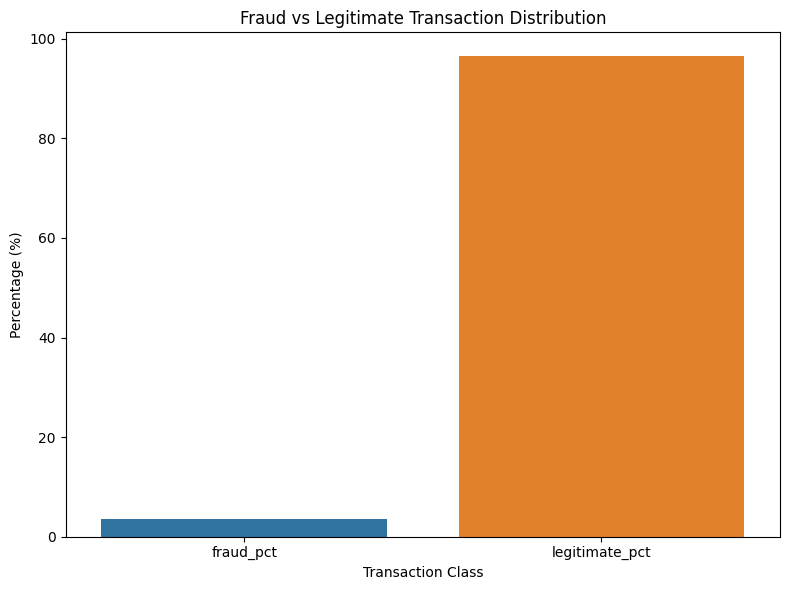

,class,percentage
0,fraud_pct,3.5
1,legitimate_pct,96.5


In [29]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

fraud_distribution = (target_distribution.loc[["fraud_pct", "legitimate_pct"], :].copy().rename(columns={0: "percentage"}))

fraud_distribution.index.name = "class"
fraud_distribution = fraud_distribution.reset_index()

plt.figure(figsize=(8, 6))
ax = sns.barplot(data=fraud_distribution, x="class", y="percentage", hue="class", legend = False)
ax.set_title("Fraud vs Legitimate Transaction Distribution")
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Percentage (%)")
plt.tight_layout()
plt.xticks()
plt.show()

fraud_distribution


**The train_transaction dataset contains 590,540 transactions of which 20,663 (3.5%) are fraudulent and 569,877 (96.50) are legitimate. This means legitimate transactions outnumber the fraudulent ones by about 27.6 to 1. Meaning for every about 28 transaction one trasaction is fraudulent. Also the fraud system should rank cases by risk so that investigators can prioritizely fraud while making the best use of limited review capacity and resources. The target classes are imbalanced. The accuracy alone may not give clear picture of the model performance. Based on this ill evaluate how the model detects fraud using metrics such as recall, precision and PR-AUC**

### 2: The Temporal Structure

**Objective:** To determine if fraud behaviour changes over time

**Temporal Variable:** TransactionDT

- This variable represent elapsed time in seconds from a reference point. It is not an actual calender timestamp